# Import Environment variables

In [1]:
%run /home/jupyter/repos/Multi-trait-GWAS-in-admixed-populations/notebooks/Setting_Env_Variables.ipynb

Found bucket: id=rw-migration-aou-rw-f7a4d148, bucketName=rw-migration-aou-rw-f7a4d148
-> Assigned migration variables (ID: rw-migration-aou-rw-f7a4d148)
Found bucket: id=temporary-workspace-bucket, bucketName=temporary-workspace-bucket-wb-perky-cabbage-8342
Found bucket: id=workspace-bucket, bucketName=workspace-bucket-wb-perky-cabbage-8342
✅ Successfully identified latest dataset: wb-silky-artichoke-2408.C2024Q3R9

Variables extracted:
GOOGLE_CLOUD_PROJECT: wb-perky-cabbage-8342
WORKSPACE_BUCKET: gs://workspace-bucket-wb-perky-cabbage-8342
WORKSPACE_TEMP_BUCKET: gs://temporary-workspace-bucket-wb-perky-cabbage-8342
WORKSPACE_CDR: wb-silky-artichoke-2408.C2024Q3R9
bucket_aou_tutorial: NOT FOUND
bucket_id_aou_tutorial: NOT FOUND
bucket_migrated: gs://rw-migration-aou-rw-f7a4d148
bucket_id_migrated: rw-migration-aou-rw-f7a4d148

✅ Saved to /home/jupyter/.bashrc
C2024Q3R9 BQ_DATASET
Multi-trait-GWAS-in-admixed-populations GIT_REPO
dataset_test2 BQ_DATASET
prep_C2024Q3R9 BQ_DATASET
rw-mig

In [2]:
%run /home/jupyter/repos/Multi-trait-GWAS-in-admixed-populations/notebooks/Setting_Env_Variables_p2.ipynb

WORKSPACE_CDR = wb-silky-artichoke-2408.C2024Q3R9
WORKSPACE_BUCKET = gs://workspace-bucket-wb-perky-cabbage-8342
GOOGLE_PROJECT = wb-perky-cabbage-8342
Done! 10 variables saved to: /home/jupyter/repos/Multi-trait-GWAS-in-admixed-populations/notebooks/Setting_Env_Variables_p2.R
Done! 10 variables saved to: /home/jupyter/repos/Multi-trait-GWAS-in-admixed-populations/notebooks/Setting_Env_Variables.sas


# Librairy

In [3]:
import os
import numpy as np
import pandas as pd
import my_function as mf

# Data's import

## PRS 298, 305 et 311

In [4]:
# get the bucket name
my_bucket = os.getenv('WORKSPACE_BUCKET')

name_of_file_in_bucket = "df_all_prs_298_305_311.csv"

df_prs = pd.read_csv(my_bucket +'/Data/'+ name_of_file_in_bucket, sep=',', low_memory=False)

## Clinical data

In [5]:
# get the bucket name
my_bucket = os.getenv('WORKSPACE_BUCKET')

name_of_file_in_bucket = "df_eur_cohorte_raw_bcsc_mammorisk.tsv"

df_eur = pd.read_csv(my_bucket +'/Data/'+ name_of_file_in_bucket, sep=',', low_memory=False)

# Data set merged

In [6]:
df_models = pd.merge(df_eur, df_prs, left_on='person_id', right_on='index', how='left')

# Split de la cohorte européenne

In [7]:
# get the bucket name
my_bucket = os.getenv('WORKSPACE_BUCKET')

name_of_file_in_bucket = "train_ids_eur.csv"

train_ids_eur = pd.read_csv(my_bucket +'/Data/'+ name_of_file_in_bucket, sep=',', low_memory=False)

In [8]:
# get the bucket name
my_bucket = os.getenv('WORKSPACE_BUCKET')

name_of_file_in_bucket = "test_ids_eur.csv"

test_ids_eur = pd.read_csv(my_bucket +'/Data/'+ name_of_file_in_bucket, sep=',', low_memory=False)

# Evaluation de performance des PRS

In [9]:
df_models.columns

Index(['person_id', 'inclusion_date', 'first_breast_cancer_date', 'delay_days',
       'age_at_inclusion', 'has_bc', 'eur_rye', 'eas_rye', 'amr_rye',
       'afr_rye', 'sas_rye', 'mid_rye', 'dominant_origin', 'ancestry_80',
       'biopsy', 'age_category', 'race_us_bcsc', 'race_us_bcsc_detail',
       'breast_cancer_family_history_first_degree', 'score_bcscRisk',
       'score_mammorisk', 'index', 'prs_298', 'risk_ratio_298',
       'num_snps_with_genotypes_298', 'num_snps_total_298', 'prs_305',
       'risk_ratio_305', 'num_snps_with_genotypes_305', 'num_snps_total_305',
       'prs_311', 'risk_ratio_311', 'num_snps_with_genotypes_311',
       'num_snps_total_311'],
      dtype='object')

In [10]:
df_models_prs = df_models.copy()

df_models_prs = df_models_prs[[
    'person_id','has_bc',
    'prs_298','risk_ratio_298',
    'prs_305','risk_ratio_305',
    'prs_311','risk_ratio_311',
    ]]

## PRS 298

### Calcul du alpha recalibré sur le train set (25%)

1. Le problème du biais de sur-optimisation (Data Leakage)

Au point 2, tu calcules `prs_prob_recalib` directement sur tout le dataframe `df_models`.
* Problème : Si `df_models` contient à la fois le Train (25%) et le Test (75%), réinjecter la probabilité réétalonnée globale risque d'introduire des biais lors des analyses ultérieures.
* Bonne pratique : Applique la transformation uniquement sur le jeu de Test (75%) pour évaluer la calibration sur des données totalement indépendantes.

2. Le contrôle de l'âge à l'inclusion / temps de suivi

Une régression logistique simple $Y \sim \text{PRS}$ sur une cohorte d'âge hétérogène ($40\text{--}74$ ans) suppose que toutes les femmes ont le même risque de base, ce qui est faux.
* Ajustement : Il est recommandé d'inclure au minimum l'âge à l'inclusion (ou l'âge de référence $T_{\text{réf}}$) comme covariable dans l'apprentissage de la recalibration, ou d'utiliser un modèle avec offset pour caler l'intercept sur l'incidence de la tranche d'âge.

3. La vérification du recentrage du Z-scoreAvant de passer prs_298 dans la régression logistique, assure-toi que ton PRS a bien été centré-réduit ($\mu = 0, \sigma = 1$) sur la population témoin ($Y=0$) du jeu Train. Si le score Z brut dévie légèrement (ex. $\mu = 0{,}12$), l'intercept $\alpha$ absorbant cette déviation sera légèrement décalé.

In [11]:
# 1. Recalibration univariée (Apprentissage de alpha et beta sur Train 25%)
df_models_prs_298, params_298 = mf.recalibrate_prs_only(
    df_data=df_models_prs,
    train_ids=train_ids_eur,
    test_ids=test_ids_eur,
    prs_col="prs_298",
)

=== RECALIBRATION SEULE : PRS_298 ===
• Intercept (α) : -5.0990
• Pente PRS (β) : 0.2789



Ces paramètres sont très cohérents avec la théorie biostatistique :

* $\mu = 0{,}0503 \approx 0$ : La moyenne des témoins est très proche de zéro, ce qui confirme que la distribution brute du PRS dans ta population contrôle était déjà globalement bien centrée.
* $\sigma = 0{,}6123 \neq 1$ : L'écart-type est inférieur à $1$, ce qui montre que la variance brute du PRS dans la cohorte est plus resserrée que celle de la population source (UK Biobank / BCAC).
*
* Cette étape de recentrage est donc pleinement justifiée : en divisant par $\sigma = 0{,}6123$, tu restructures l'échelle pour qu'un écart de $+1$ unité de `prs_298_z` corresponde exactement à $+1$ écart-type de risque génétique chez les témoins.

### Comparaison des calibration (brut vs recalibration)

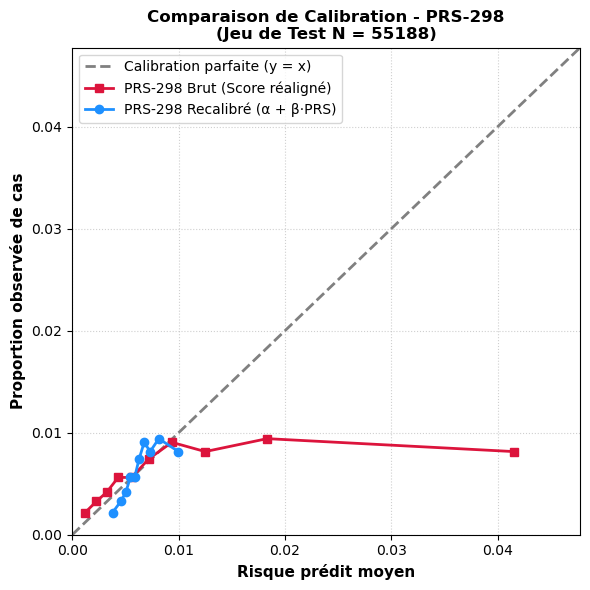

In [12]:
# 2. Courbe de calibration comparative finale
mf.compare_prs_calibration(
    df_data=df_models_prs_298,
    train_ids=train_ids_eur,
    test_ids=test_ids_eur,
    prs_col="prs_298",
    recalib_col=params_298["recalib_col"],
    model_name="PRS-298",
)

### Evaluation après recalibration

**Pourquoi le ratio $O/E$ réapparaît maintenant ?**

* **Sur le PRS brut alone :** Tu as raison, le ratio $O/E$ n'existe pas car un Z-score ou un Risk Ratio relatif n'est pas une probabilité. On ne peut pas sommer des Z-scores pour obtenir un « nombre de cas attendus ». C'est pour cela que la fonction `evaluate_and_plot_raw_prs` ne contenait aucun ratio $O/E$.
* **Après la fonction `recalibrate_prs_model` :** La régression logistique bivariée ($Y \sim \text{PRS}_z + \text{Âge}$) a transformé le Z-score en une probabilité absolue de maladie ($\hat{p} \in [0, 1]$) stockée dans prs_298_prob_recalib.
* **Sur les probabilités absolues :** Une fois converti en probabilité, le score prend la même forme mathématique qu'un modèle clinique (comme Mammorisk ou BCSC). Il devient alors possible et pertinent de calculer $E = \sum \hat{p}_i$ et d'afficher le ratio $O/E$ pour vérifier si le modèle logistique est bien calé sur l'incidence globale du jeu de test.

**La distinction clé à retenir**

* **PRS Brut (`prs_298`) :** Score relatif ($Z$). Pas de probabilité absolue, donc pas de métrique $O/E$ (on évalue uniquement l'AUC et les Odds Ratios par quintile via `evaluate_and_plot_raw_prs`).
* **PRS Recalibré (`prs_298_prob_recalib`) :** Probabilité absolue réétalonnée. La métrique $O/E$ devient valide et indispensable pour vérifier que la recalibration logistique a fonctionné ($O/E \approx 1{,}00$).

* Ton intuition était parfaite : le PRS pur n'a pas de $O/E$, c'est l'étape de conversion logistique en probabilité qui lui donne une échelle absolue sur laquelle le $O/E$ prend tout son sens.

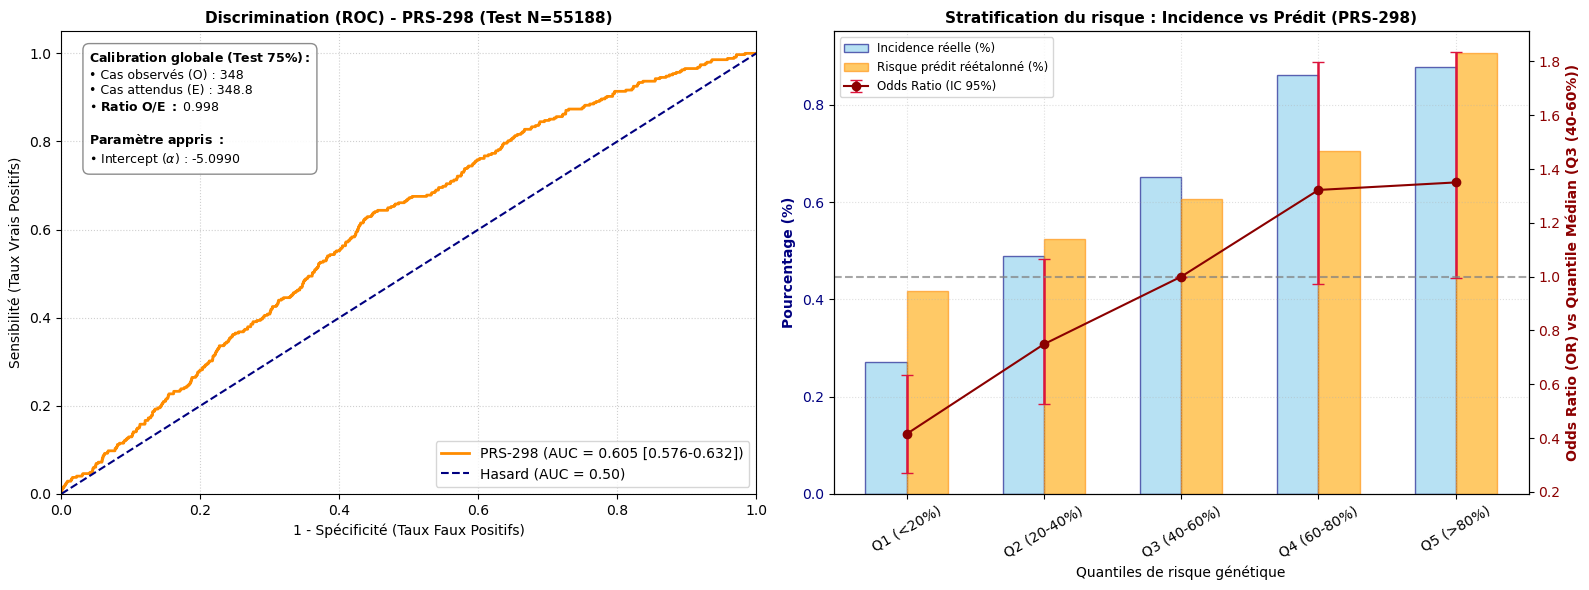

In [13]:
# 3. Évaluation complète : Discrimination (ROC), Stratification (OR) et Recalibration (O/E)
metrics_298, df_eval_298 = mf.evaluate_and_plot_model(
    df_data=df_models_prs_298,
    test_ids=test_ids_eur,
    score_col=params_298["recalib_col"],
    target_col="has_bc",
    id_col="person_id",
    model_name="PRS-298",
    alpha_val=params_298["alpha"],
)

## PRS 305

### Calcul du alpha recalibré sur le train set (25%)

In [14]:
# 1. Recalibration univariée (Apprentissage de alpha et beta sur Train 25%)
df_models_prs_305, params_305 = mf.recalibrate_prs_only(
    df_data=df_models_prs,
    train_ids=train_ids_eur,
    test_ids=test_ids_eur,
    prs_col="prs_305",
)

=== RECALIBRATION SEULE : PRS_305 ===
• Intercept (α) : -5.1001
• Pente PRS (β) : 0.2830



### Comparaison des calibration (brut vs recalibration)

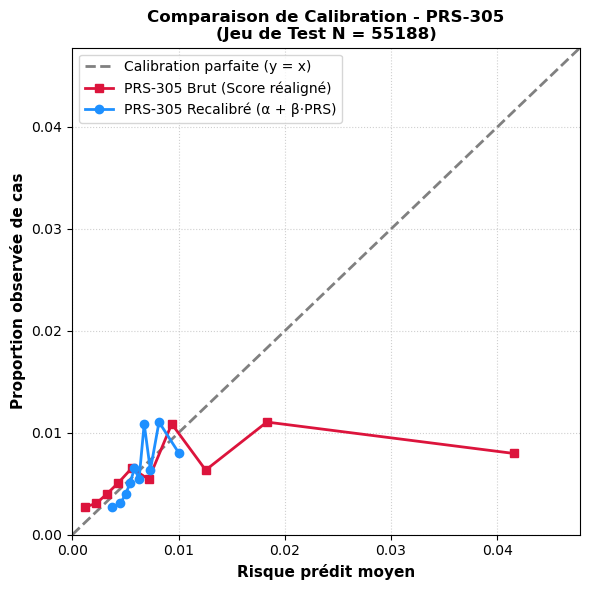

In [15]:
# 2. Courbe de calibration comparative finale
mf.compare_prs_calibration(
    df_data=df_models_prs_305,
    train_ids=train_ids_eur,
    test_ids=test_ids_eur,
    prs_col="prs_305",
    recalib_col=params_305["recalib_col"],
    model_name="PRS-305",
)

### Evaluation après recalibration

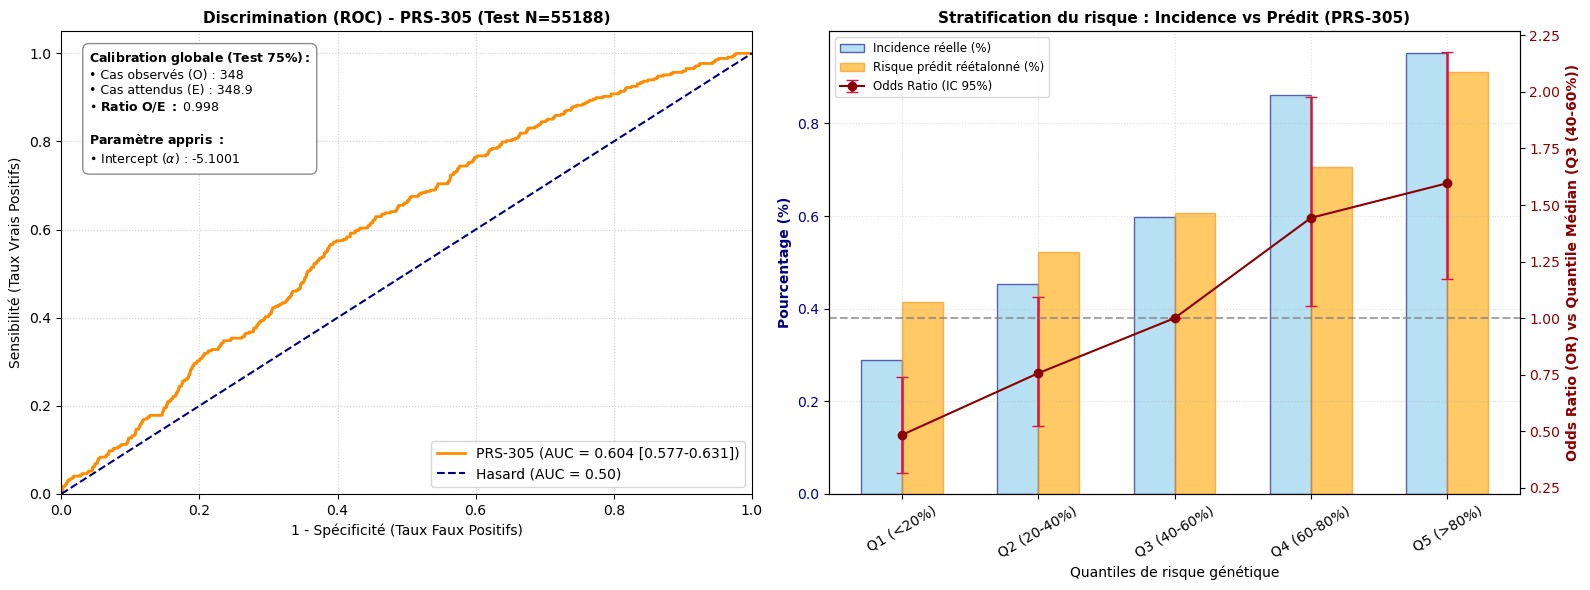

In [16]:
# 3. Évaluation complète : Discrimination (ROC), Stratification (OR) et Recalibration (O/E)
metrics_305, df_eval_305 = mf.evaluate_and_plot_model(
    df_data=df_models_prs_305,
    test_ids=test_ids_eur,
    score_col=params_305["recalib_col"],
    target_col="has_bc",
    id_col="person_id",
    model_name="PRS-305",
    alpha_val=params_305["alpha"],
)

## PRS 311

### Calcul du alpha recalibré sur le train set (25%)

In [17]:
# 1. Recalibration univariée (Apprentissage de alpha et beta sur Train 25%)
df_models_prs_311, params_311 = mf.recalibrate_prs_only(
    df_data=df_models_prs,
    train_ids=train_ids_eur,
    test_ids=test_ids_eur,
    prs_col="prs_311",
)

=== RECALIBRATION SEULE : PRS_311 ===
• Intercept (α) : -5.0976
• Pente PRS (β) : 0.2741



### Comparaison des calibration (brut vs recalibration)

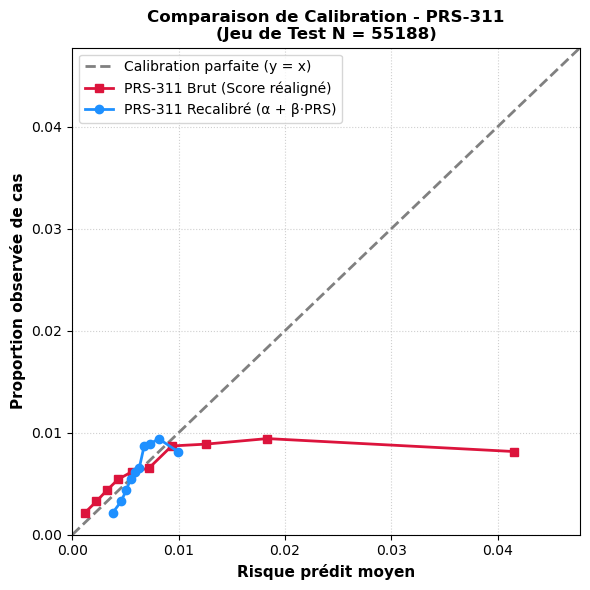

In [18]:
# 2. Courbe de calibration comparative finale
mf.compare_prs_calibration(
    df_data=df_models_prs_311,
    train_ids=train_ids_eur,
    test_ids=test_ids_eur,
    prs_col="prs_311",
    recalib_col=params_311["recalib_col"],
    model_name="PRS-311",
)

### Evaluation après recalibration

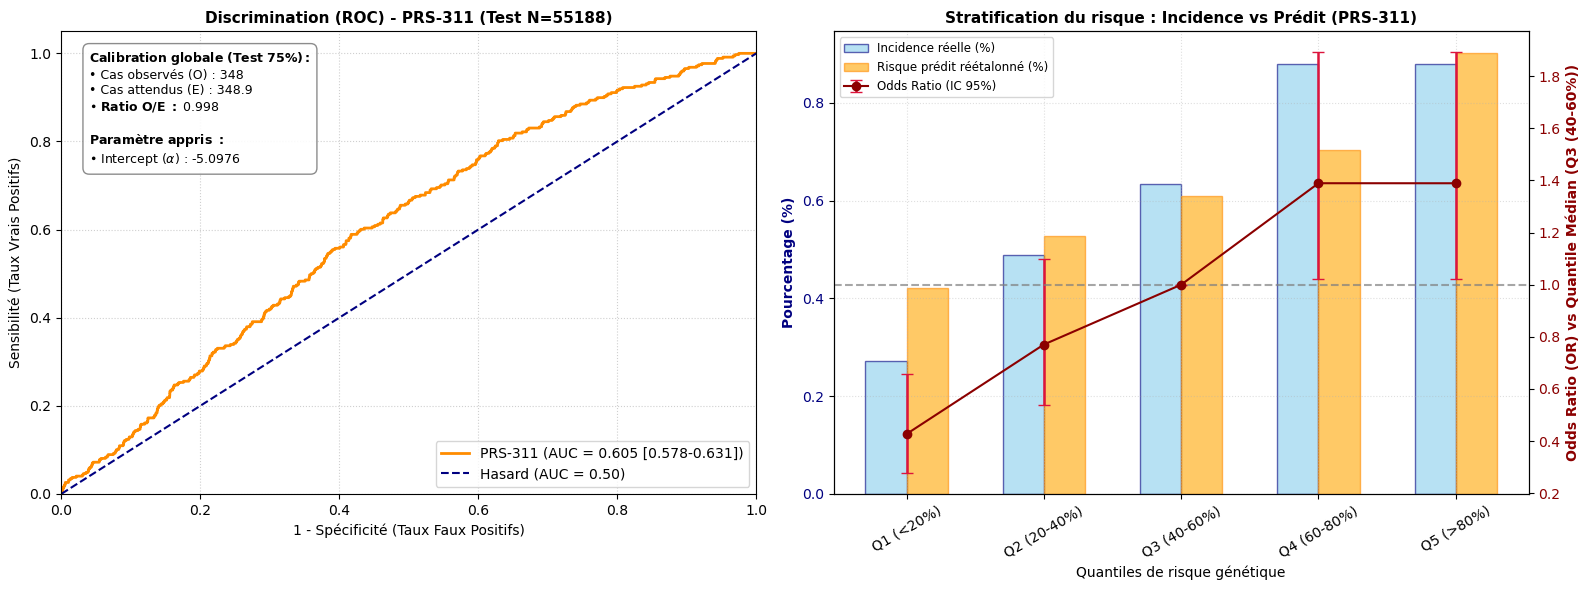

In [19]:
# 3. Évaluation complète : Discrimination (ROC), Stratification (OR) et Recalibration (O/E)
metrics_311, df_eval_311 = mf.evaluate_and_plot_model(
    df_data=df_models_prs_311,
    test_ids=test_ids_eur,
    score_col=params_311["recalib_col"],
    target_col="has_bc",
    id_col="person_id",
    model_name="PRS-311",
    alpha_val=params_311["alpha"],
)

# Fusion des résultats

In [20]:
df_prs = pd.merge(
    df_eval_298[['person_id','prs_298','prs_298_z','prs_298_prob_recalib_only','PRS-298_risk_group']],
    df_eval_305[['person_id','prs_305','prs_305_z','prs_305_prob_recalib_only','PRS-305_risk_group']],
    on='person_id',
    how='left'
)

In [21]:
df_prs = pd.merge(
    df_prs,
    df_eval_311[['person_id','prs_311','prs_311_z','prs_311_prob_recalib_only','PRS-311_risk_group']],
    on='person_id',
    how='left'
)

# Data's export

## Europeen cohort + raw PRS results

In [22]:
destination_filename = 'Datas/df_eur_cohorte_raw_bcsc_mammorisk_prs_298_305_311.tsv'
df_models.to_csv(destination_filename, index=False)

# Récupère le nom du bucket Google Cloud depuis la variable d’environnement
my_bucket = os.getenv('WORKSPACE_BUCKET')

# Copie le fichier TSV local dans le dossier "Data" du bucket
args = ["gsutil", "cp", f"./{destination_filename}", f"{my_bucket}/Data"]
output = subprocess.run(args, capture_output=True)

# Affiche les éventuelles erreurs retournées par gsutil
output.stderr

b'Copying file://./Datas/df_eur_cohorte_raw_bcsc_mammorisk_prs_298_305_311.tsv [Content-Type=text/tab-separated-values]...\n/ [0 files][    0.0 B/ 24.2 MiB]                                                \r-\r- [1 files][ 24.2 MiB/ 24.2 MiB]                                                \r\\\r\nOperation completed over 1 objects/24.2 MiB.                                     \n'

## test cohort with the PRS's recalibration results

In [23]:
destination_filename = 'Datas/df_test_eur_prs298_305_311_recalib.tsv'
df_prs.to_csv(destination_filename, index=False)

# Récupère le nom du bucket Google Cloud depuis la variable d’environnement
my_bucket = os.getenv('WORKSPACE_BUCKET')

# Copie le fichier TSV local dans le dossier "Data" du bucket
args = ["gsutil", "cp", f"./{destination_filename}", f"{my_bucket}/Data"]
output = subprocess.run(args, capture_output=True)

# Affiche les éventuelles erreurs retournées par gsutil
output.stderr

b'Copying file://./Datas/df_test_eur_prs298_305_311_recalib.tsv [Content-Type=text/tab-separated-values]...\n/ [0 files][    0.0 B/ 11.4 MiB]                                                \r/ [1 files][ 11.4 MiB/ 11.4 MiB]                                                \r\nOperation completed over 1 objects/11.4 MiB.                                     \n'